<a href="https://colab.research.google.com/github/FrancoPanico/glioblastoma-mri-seg-mgmt/blob/White_Stripe/White_Stripe_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WhiteStripe Intensity Normalization Pipeline
## 1. Setup, caricamento metadati e analisi del Domain Shift grezzo

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


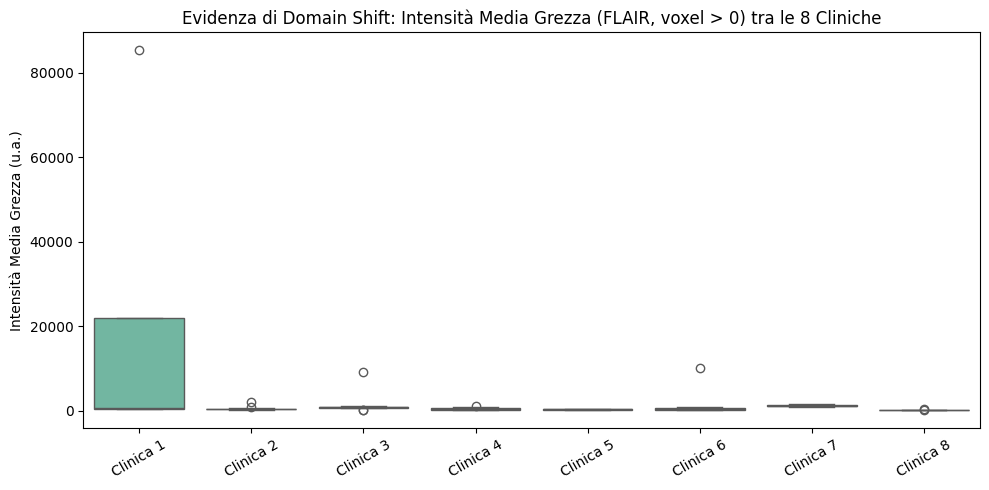

In [ ]:
from google.colab import drive
import os
import pandas as pd
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
from concurrent.futures import ThreadPoolExecutor

drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/Assignment_26_27'
IMG_DIR = os.path.join(DATA_DIR, 'training_images')
META_PATH = os.path.join(DATA_DIR, 'training_metadata.xlsx')

df_meta = pd.read_excel(META_PATH)
df_meta.rename(columns={df_meta.columns[0]: 'ID', df_meta.columns[1]: 'MGMT', df_meta.columns[2]: 'Cohort'}, inplace=True)
df_meta['ID'] = df_meta['ID'].astype(int)
df_meta['Cohort'] = df_meta['Cohort'].astype(int)

# Campionamento stratificato per clinica (fino a 15 pazienti per centro) per valutare lo shift d'intensità
sampled_rows = [group.sample(min(15, len(group)), random_state=42) for _, group in df_meta.groupby('Cohort')]
df_sample = pd.concat(sampled_rows)

def extract_raw_stats(row):
    p_id = str(int(row['ID']))
    # Carica esplicitamente 'flair.nii.gz' (ignora eventuali duplicati come 'flair (1).nii.gz' nell'ID 813)
    flair_path = os.path.join(IMG_DIR, p_id, 'flair.nii.gz')
    data = nib.load(flair_path).get_fdata()
    brain_voxels = data[data > 0]
    return {
        'ID': int(row['ID']),
        'Cohort': f"Clinica {int(row['Cohort'])}",
        'Cohort_Num': int(row['Cohort']),
        'Mean_Raw': np.mean(brain_voxels),
        'Std_Raw': np.std(brain_voxels),
        'P99_Raw': np.percentile(brain_voxels, 99)
    }

with ThreadPoolExecutor(max_workers=16) as executor:
    stats_list = list(executor.map(extract_raw_stats, [r for _, r in df_sample.iterrows()]))

df_int = pd.DataFrame(stats_list).sort_values('Cohort_Num')

# Visualizzazione del Domain Shift a schermo
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_int, x='Cohort', y='Mean_Raw', hue='Cohort', palette='Set2', legend=False)
plt.title("Evidenza di Domain Shift: Intensità Media Grezza (FLAIR, voxel > 0) tra le 8 Cliniche")
plt.ylabel("Intensità Media Grezza (u.a.)")
plt.xlabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 2. Implementazione WhiteStripe + FWHM (con modalità ibrida T2)

In [ ]:
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks, peak_widths

def compute_whitestripe_params(vol_data, modality='t1', width=0.10):
    """
    Stima la maschera NAWM, la media (mu_ws) e la deviazione standard robusta (sigma_ws)
    tramite Kernel Density Estimation (KDE) e FWHM del picco della sostanza bianca.
    """
    brain_mask = vol_data > 0
    brain_voxels = vol_data[brain_mask]

    # Filtra solo gli artefatti estremi (>99.5°) per non distorcere la KDE
    p005, p995 = np.percentile(brain_voxels, [0.5, 99.5])
    clean_voxels = brain_voxels[(brain_voxels >= p005) & (brain_voxels <= p995)]

    if len(clean_voxels) > 50000:
        rng = np.random.default_rng(42)
        sample_voxels = rng.choice(clean_voxels, size=50000, replace=False)
    else:
        sample_voxels = clean_voxels

    kde = gaussian_kde(sample_voxels)
    x_grid = np.linspace(p005, p995, 1000)
    density = kde(x_grid)

    peaks, _ = find_peaks(density, prominence=np.max(density) * 0.05)

    if len(peaks) == 0:
        peak_idx = int(np.argmax(density))
    else:
        if modality.lower() in ['t1', 't1ce']:
            # In T1/T1ce la sostanza bianca è il picco più intenso (a destra)
            peak_idx = int(peaks[-1])
        else:
            # In FLAIR è il picco modale principale assoluto
            peak_idx = int(peaks[np.argmax(density[peaks])])

    ws_mode = x_grid[peak_idx]

    # Calcola FWHM (Full Width at Half Maximum) del picco per ottenere la sigma gaussiana reale della NAWM
    widths_res = peak_widths(density, [peak_idx], rel_height=0.5)
    fwhm_in_units = widths_res[0][0] * (x_grid[1] - x_grid[0])
    sigma_fwhm = fwhm_in_units / 2.3548  # Relazione standard FWHM = 2.355 * sigma

    # Maschera spaziale della White Stripe (+-10% attorno al picco) per visualizzazione e T2 hybrid
    mode_quantile = np.mean(clean_voxels <= ws_mode)
    val_low, val_high = np.quantile(clean_voxels, [max(0.02, mode_quantile - width), min(0.98, mode_quantile + width)])
    ws_mask = brain_mask & (vol_data >= val_low) & (vol_data <= val_high)

    # Fallback se il picco è asimmetrico/troncato
    sigma_ws = max(sigma_fwhm, np.std(vol_data[ws_mask]) * 2.5) + 1e-8
    return ws_mask, ws_mode, sigma_ws

def normalize_patient_whitestripe(patient_dir, width=0.10):
    """
    Normalizza le 4 sequenze con WhiteStripe + FWHM (Hybrid T1-guided per T2).
    """
    modalities = ['t1', 't1ce', 't2', 'flair']
    raw_vols = {}
    norm_vols = {}

    for mod in modalities:
        path = os.path.join(patient_dir, f"{mod}.nii.gz")
        raw_vols[mod] = nib.load(path).get_fdata().astype(np.float32)

    # Maschera NAWM da T1 (usata anche per T2)
    t1_ws_mask, t1_mu, t1_sigma = compute_whitestripe_params(raw_vols['t1'], modality='t1', width=width)

    for mod in modalities:
        vol = raw_vols[mod]
        brain_mask = vol > 0

        if mod == 't1':
            mu_ws, sigma_ws = t1_mu, t1_sigma
        elif mod == 't2':
            # Hybrid WhiteStripe: stima mu e sigma di T2 sui voxel NAWM individuati da T1
            t2_nawm = vol[t1_ws_mask]
            mu_ws = np.median(t2_nawm)
            # IQR / 1.349 è lo stimatore robusto della deviazione standard gaussiana
            sigma_ws = ((np.percentile(t2_nawm, 75) - np.percentile(t2_nawm, 25)) / 1.349) * 2.0 + 1e-8
        else:
            _, mu_ws, sigma_ws = compute_whitestripe_params(vol, modality=mod, width=width)

        norm_vol = np.zeros_like(vol, dtype=np.float32)
        # Clipping solo degli spike patologici/artefatti oltre 99.9° percentile del volume
        p999 = np.percentile(vol[brain_mask], 99.9)
        vol_clipped = np.minimum(vol, p999)

        norm_vol[brain_mask] = (vol_clipped[brain_mask] - mu_ws) / sigma_ws
        norm_vols[mod] = norm_vol

    return norm_vols, raw_vols, t1_ws_mask

## 3. Controllo qualità visivo sul singolo paziente e confronto multi-clinica

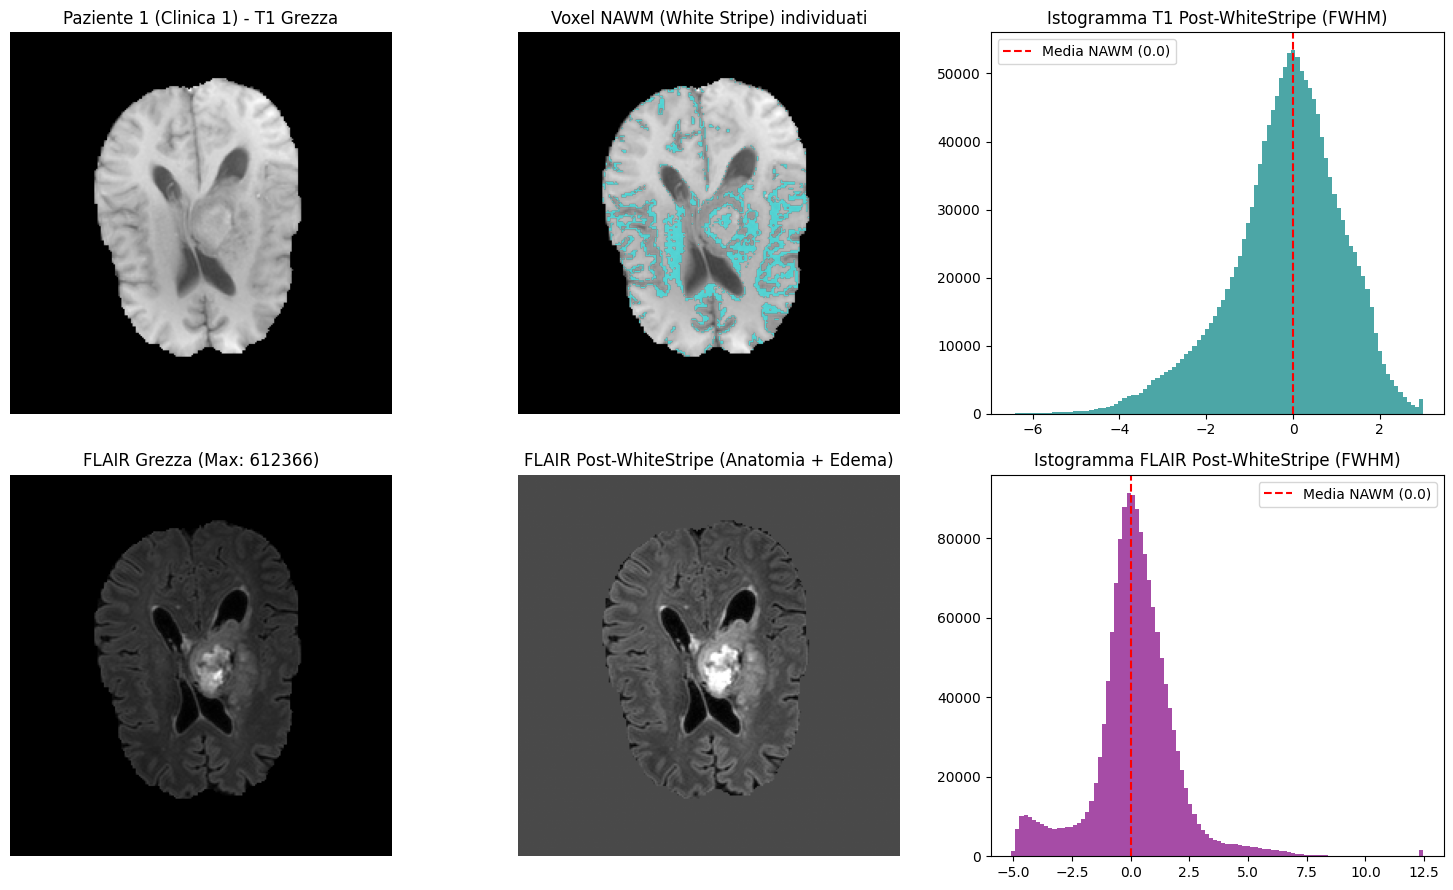

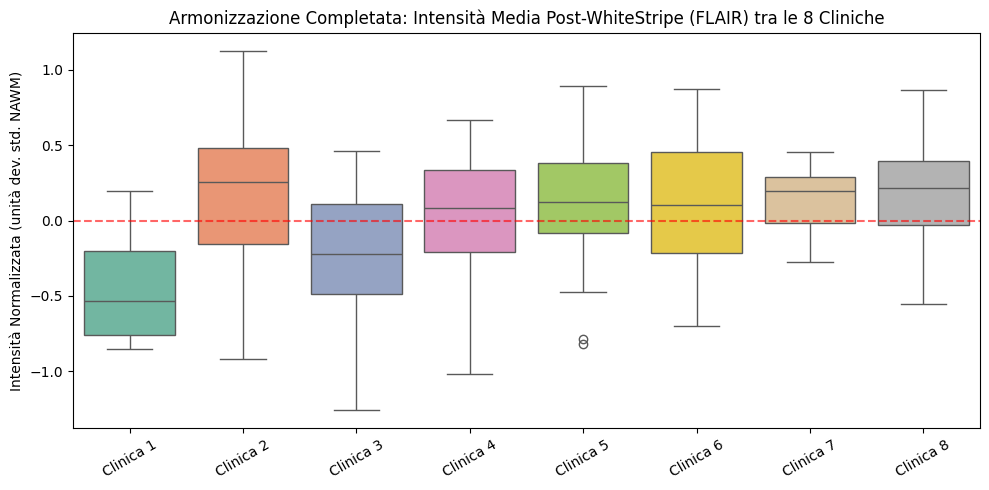

In [ ]:
# 1. Ispezione dettagliata su un paziente della Clinica 1 (quella con intensità estreme)
clinica1_id = str(int(df_meta[df_meta['Cohort'] == 1]['ID'].iloc[0]))
p_dir = os.path.join(IMG_DIR, clinica1_id)

norm_vols, raw_vols, t1_ws_mask = normalize_patient_whitestripe(p_dir)

z = 78
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Riga 1: T1
axes[0, 0].imshow(np.rot90(raw_vols['t1'][:, :, z]), cmap='gray')
axes[0, 0].set_title(f"Paziente {clinica1_id} (Clinica 1) - T1 Grezza")
axes[0, 0].axis('off')

axes[0, 1].imshow(np.rot90(raw_vols['t1'][:, :, z]), cmap='gray')
axes[0, 1].imshow(np.rot90(np.ma.masked_where(~t1_ws_mask[:, :, z], t1_ws_mask[:, :, z])), cmap='cool', alpha=0.5)
axes[0, 1].set_title("Voxel NAWM (White Stripe) individuati")
axes[0, 1].axis('off')

axes[0, 2].hist(norm_vols['t1'][norm_vols['t1'] != 0], bins=100, color='teal', alpha=0.7)
axes[0, 2].axvline(0, color='red', linestyle='--', label='Media NAWM (0.0)')
axes[0, 2].set_title("Istogramma T1 Post-WhiteStripe (FWHM)")
axes[0, 2].legend()

# Riga 2: FLAIR
axes[1, 0].imshow(np.rot90(raw_vols['flair'][:, :, z]), cmap='gray')
axes[1, 0].set_title(f"FLAIR Grezza (Max: {raw_vols['flair'].max():.0f})")
axes[1, 0].axis('off')

axes[1, 1].imshow(np.rot90(norm_vols['flair'][:, :, z]), cmap='gray')
axes[1, 1].set_title("FLAIR Post-WhiteStripe (Anatomia + Edema)")
axes[1, 1].axis('off')

axes[1, 2].hist(norm_vols['flair'][norm_vols['flair'] != 0], bins=100, color='purple', alpha=0.7)
axes[1, 2].axvline(0, color='red', linestyle='--', label='Media NAWM (0.0)')
axes[1, 2].set_title("Istogramma FLAIR Post-WhiteStripe (FWHM)")
axes[1, 2].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_whitestripe_single_patient_check.png'), dpi=300)
plt.show()

# 2. Verifica Multi-Clinica Post-WhiteStripe (usando direttamente mu_ws e sigma_ws con FWHM)
def extract_norm_stats(row):
    p_id = str(int(row['ID']))
    cohort_num = int(row['Cohort'])
    p_path = os.path.join(IMG_DIR, p_id)

    vol = nib.load(os.path.join(p_path, 'flair.nii.gz')).get_fdata().astype(np.float32)
    brain_mask = vol > 0

    # Estrae direttamente mu_ws e sigma_ws calcolati con FWHM
    _, mu_ws, sigma_ws = compute_whitestripe_params(vol, modality='flair', width=0.10)

    p999 = np.percentile(vol[brain_mask], 99.9)
    vol_clipped = np.minimum(vol, p999)
    norm_brain = (vol_clipped[brain_mask] - mu_ws) / sigma_ws

    return {
        'Cohort': f"Clinica {cohort_num}",
        'Cohort_Num': cohort_num,
        'Mean_WhiteStripe': np.mean(norm_brain)
    }

with ThreadPoolExecutor(max_workers=16) as executor:
    norm_stats_list = list(executor.map(extract_norm_stats, [r for _, r in df_sample.iterrows()]))

df_norm_int = pd.DataFrame(norm_stats_list).sort_values('Cohort_Num')

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_norm_int, x='Cohort', y='Mean_WhiteStripe', hue='Cohort', palette='Set2', legend=False)
plt.axhline(0, color='red', linestyle='--', alpha=0.6)
plt.title("Armonizzazione Completata: Intensità Media Post-WhiteStripe (FLAIR) tra le 8 Cliniche")
plt.ylabel("Intensità Normalizzata (unità dev. std. NAWM)")
plt.xlabel("")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_whitestripe_harmony_check.png'), dpi=300)
plt.show()

## 4. Validazione istogrammi medi post-WhiteStripe (4 sequenze × 8 cliniche)

Elaborazione griglia 4x8:   0%|          | 0/109 [00:00<?, ?it/s]

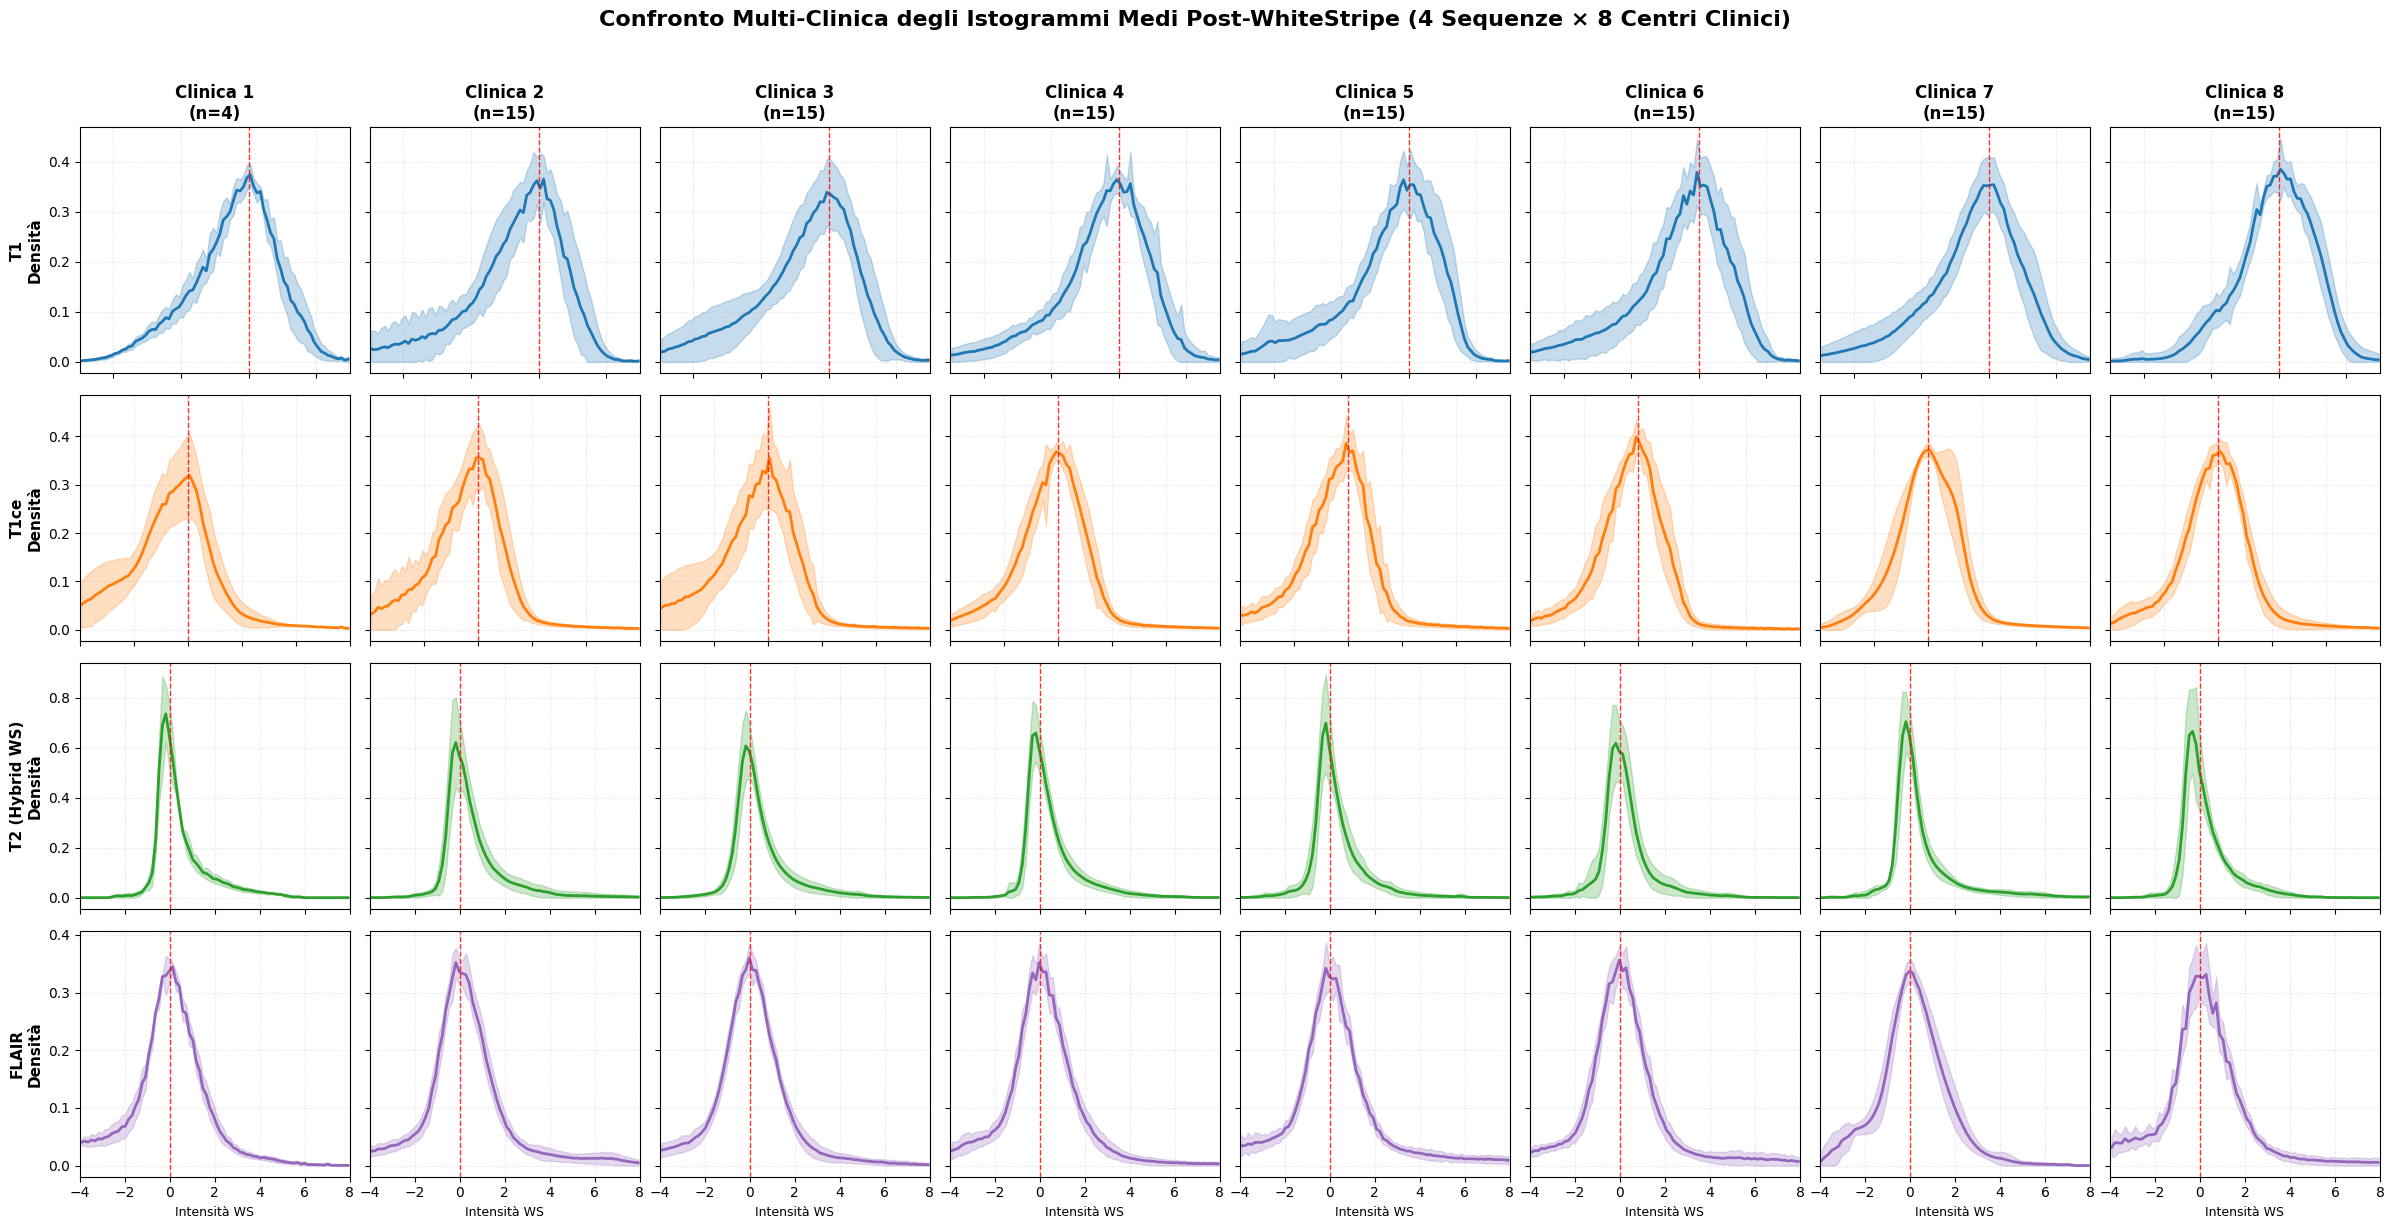

In [ ]:
from tqdm.auto import tqdm

modalities = ['t1', 't1ce', 't2', 'flair']
mod_titles = ['T1', 'T1ce', 'T2 (Hybrid WS)', 'FLAIR']
cohorts = sorted(df_meta['Cohort'].unique())

# Range fisso sull'asse X per ogni sequenza per confrontabilità diretta tra colonne
x_ranges = {
    't1': (-5.0, 3.0),
    't1ce': (-4.0, 6.0),
    't2': (-4.0, 8.0),
    'flair': (-4.0, 8.0)
}
num_bins = 80

# Campionamento fino a 15 pazienti per clinica (tutti e 4 per la Clinica 1)
sampled_patients = [df_meta[df_meta['Cohort'] == c].sample(min(15, len(df_meta[df_meta['Cohort'] == c])), random_state=42) for c in cohorts]
df_grid_sample = pd.concat(sampled_patients)

def compute_patient_histograms(row):
    p_id = str(int(row['ID']))
    cohort_num = int(row['Cohort'])
    p_dir = os.path.join(IMG_DIR, p_id)

    norm_vols, _, _ = normalize_patient_whitestripe(p_dir, width=0.10)

    patient_hists = {'Cohort': cohort_num}
    for mod in modalities:
        vol = norm_vols[mod]
        brain_voxels = vol[vol != 0]
        counts, _ = np.histogram(brain_voxels, bins=num_bins, range=x_ranges[mod], density=True)
        patient_hists[mod] = counts
    return patient_hists

with ThreadPoolExecutor(max_workers=16) as executor:
    all_hists = list(tqdm(
        executor.map(compute_patient_histograms, [r for _, r in df_grid_sample.iterrows()]),
        total=len(df_grid_sample),
        desc="Elaborazione griglia 4x8"
    ))

fig, axes = plt.subplots(nrows=4, ncols=8, figsize=(24, 12), sharey='row')
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']

for row_idx, mod in enumerate(modalities):
    r_min, r_max = x_ranges[mod]
    bin_edges = np.linspace(r_min, r_max, num_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    for col_idx, c in enumerate(cohorts):
        ax = axes[row_idx, col_idx]

        c_hists = np.array([item[mod] for item in all_hists if item['Cohort'] == c])
        mean_hist = np.mean(c_hists, axis=0)
        std_hist = np.std(c_hists, axis=0)

        ax.plot(bin_centers, mean_hist, color=colors[row_idx], linewidth=2)
        ax.fill_between(bin_centers, np.maximum(0, mean_hist - std_hist), mean_hist + std_hist,
                        color=colors[row_idx], alpha=0.25)
        ax.axvline(0, color='red', linestyle='--', linewidth=1, alpha=0.8)

        if row_idx == 0:
            ax.set_title(f"Clinica {c}\n(n={len(c_hists)})", fontsize=12, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(f"{mod_titles[row_idx]}\nDensità", fontsize=11, fontweight='bold')

        ax.set_xlim(r_min, r_max)
        ax.grid(True, linestyle=':', alpha=0.4)

        if row_idx < 3:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel("Intensità WS", fontsize=9)

plt.suptitle("Confronto Multi-Clinica degli Istogrammi Medi Post-WhiteStripe (4 Sequenze × 8 Centri Clinici)",
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 5. Estrazione e salvataggio parametri WhiteStripe su tutti i 1.384 pazienti

In [ ]:
import os
import numpy as np
import pandas as pd
import nibabel as nib
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

PROJECT_DIR = '/content/drive/MyDrive/Glioblastoma-project'
DATA_OUT_DIR = os.path.join(PROJECT_DIR, 'data')
os.makedirs(DATA_OUT_DIR, exist_ok=True)

DATA_DIR = '/content/drive/MyDrive/Assignment_26_27'
IMG_DIR = os.path.join(DATA_DIR, 'training_images')
META_PATH = os.path.join(DATA_DIR, 'training_metadata.xlsx')
CSV_OUT_PATH = os.path.join(DATA_OUT_DIR, 'whitestripe_params.csv')

MODALITIES = ['t1', 't1ce', 't2', 'flair']

def extract_patient_ws_params(patient_dir: str, width: float = 0.10) -> dict:
    """
    Calcola e restituisce un dizionario con i parametri (mu, sigma, p999)
    per tutte e 4 le sequenze di un singolo paziente (usando compute_whitestripe_params).
    """
    patient_id = int(os.path.basename(patient_dir))
    raw_vols = {}
    for mod in MODALITIES:
        path = os.path.join(patient_dir, f"{mod}.nii.gz")
        raw_vols[mod] = nib.load(path).get_fdata().astype(np.float32)

    t1_ws_mask, t1_mu, t1_sigma = compute_whitestripe_params(raw_vols['t1'], modality='t1', width=width)

    params = {'ID': patient_id}
    for mod in MODALITIES:
        vol = raw_vols[mod]
        brain_mask = vol > 0

        if mod == 't1':
            mu_ws, sigma_ws = t1_mu, t1_sigma
        elif mod == 't2':
            t2_nawm = vol[t1_ws_mask]
            mu_ws = float(np.median(t2_nawm))
            sigma_ws = float(((np.percentile(t2_nawm, 75) - np.percentile(t2_nawm, 25)) / 1.349) * 2.0 + 1e-8)
        else:
            _, mu_ws, sigma_ws = compute_whitestripe_params(vol, modality=mod, width=width)

        p999 = float(np.percentile(vol[brain_mask], 99.9))
        params[f'{mod}_mu'] = mu_ws
        params[f'{mod}_sigma'] = sigma_ws
        params[f'{mod}_p999'] = p999

    return params

df_meta = pd.read_excel(META_PATH)
df_meta.rename(columns={df_meta.columns[0]: 'ID', df_meta.columns[1]: 'MGMT', df_meta.columns[2]: 'Cohort'}, inplace=True)
patient_dirs = [os.path.join(IMG_DIR, str(int(pid))) for pid in df_meta['ID']]

print(f"Estrazione parametri WhiteStripe per {len(patient_dirs)} pazienti...")
with ThreadPoolExecutor(max_workers=16) as executor:
    results = list(tqdm(
        executor.map(extract_patient_ws_params, patient_dirs),
        total=len(patient_dirs),
        desc="Calcolo parametri WS"
    ))

df_params = pd.DataFrame(results).sort_values('ID')
# Unisce anche Cohort e MGMT per avere una tabella unica pronta all'uso
df_params = pd.merge(df_meta[['ID', 'Cohort', 'MGMT']], df_params, on='ID', how='right')
df_params.to_csv(CSV_OUT_PATH, index=False)

print(f"Completato! Tabella parametri salvata in: {CSV_OUT_PATH}")
df_params.head()